In [1]:
import os
import zipfile
from collections import Counter

zip_path = "/content/Alzheimer's dataset.zip"
extract_path = "/content/alzheimers_dataset"

# Create output folder
os.makedirs(extract_path, exist_ok=True)

# Unzip
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipped successfully to:", extract_path)

# Show first-level contents
print("\nTop-level contents:")
for item in os.listdir(extract_path):
    print("-", item)

Unzipped successfully to: /content/alzheimers_dataset

Top-level contents:
- OriginalDataset
- AugmentedAlzheimerDataset


In [2]:
import os

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for root, dirs, files in os.walk(extract_path):
    image_files = [f for f in files if f.lower().endswith(image_exts)]
    if image_files:
        print(f"\nFolder: {root}")
        print(f"Number of images: {len(image_files)}")


Folder: /content/alzheimers_dataset/OriginalDataset/MildDemented
Number of images: 896

Folder: /content/alzheimers_dataset/OriginalDataset/NonDemented
Number of images: 3200

Folder: /content/alzheimers_dataset/OriginalDataset/ModerateDemented
Number of images: 64

Folder: /content/alzheimers_dataset/OriginalDataset/VeryMildDemented
Number of images: 2240

Folder: /content/alzheimers_dataset/AugmentedAlzheimerDataset/MildDemented
Number of images: 8960

Folder: /content/alzheimers_dataset/AugmentedAlzheimerDataset/NonDemented
Number of images: 9600

Folder: /content/alzheimers_dataset/AugmentedAlzheimerDataset/ModerateDemented
Number of images: 6464

Folder: /content/alzheimers_dataset/AugmentedAlzheimerDataset/VeryMildDemented
Number of images: 8960


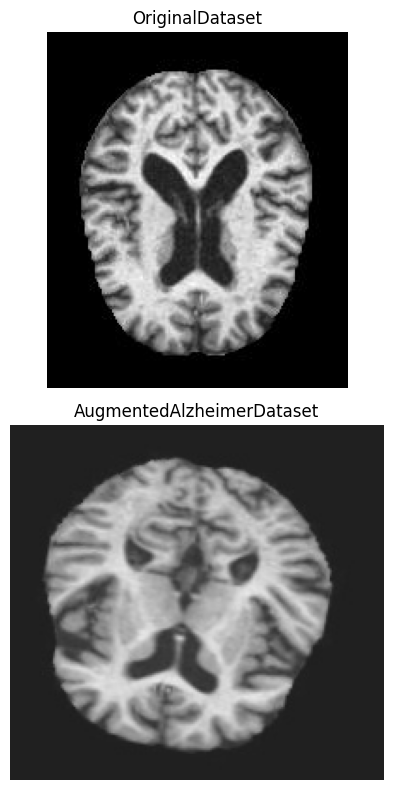

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]

plt.figure(figsize=(15, 8))

plot_idx = 1
for cls in classes:
    cls_path = os.path.join(extract_path, cls)
    images = []

    for root, dirs, files in os.walk(cls_path):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                images.append(os.path.join(root, f))

    if images:
        img_path = random.choice(images)
        img = Image.open(img_path).convert("RGB")

        plt.subplot(2, max(1, len(classes)//2 + len(classes)%2), plot_idx)
        plt.imshow(img)
        plt.title(cls)
        plt.axis("off")
        plot_idx += 1

plt.tight_layout()
plt.show()

In [4]:
from PIL import Image
from collections import Counter

size_counter = Counter()

for root, dirs, files in os.walk(extract_path):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            img_path = os.path.join(root, f)
            try:
                img = Image.open(img_path)
                size_counter[img.size] += 1
            except:
                pass

print("Most common image sizes:")
for size, count in size_counter.most_common(10):
    print(size, ":", count)

Most common image sizes:
(200, 190) : 27584
(176, 208) : 6400
(180, 180) : 6400


In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input
DATASET_PATH = "/content/alzheimers_dataset/AugmentedAlzheimerDataset"

IMG_SIZE = 224
BATCH_SIZE = 32



datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)
train_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

print("Classes:", train_data.class_indices)

Found 27188 images belonging to 4 classes.
Found 6796 images belonging to 4 classes.
Classes: {'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

IMG_SIZE = 224
NUM_CLASSES = 4

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/best_alzheimer_efficientnetb0.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=callbacks
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

Epoch 1/15
849/850 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5170 - loss: 1.2647
Epoch 1: val_accuracy improved from None to 0.72190, saving model to /content/best_alzheimer_efficientnetb0.keras

Epoch 1: finished saving model to /content/best_alzheimer_efficientnetb0.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 89s 79ms/step - accuracy: 0.5712 - loss: 1.0382 - val_accuracy: 0.7219 - val_loss: 0.6408 - learning_rate: 0.0010
Epoch 2/15
849/850 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6330 - loss: 0.8206
Epoch 2: val_accuracy improved from 0.72190 to 0.74426, saving model to /content/best_alzheimer_efficientnetb0.keras

Epoch 2: finished saving model to /content/best_alzheimer_efficientnetb0.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - accuracy: 0.6434 - loss: 0.7947 - val_accuracy: 0.7443 - val_loss: 0.5782 - learning_rate: 0.0010
Epoch 3/15
849/850 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.6691 - loss: 0.7411
Epoch 3: val_accuracy improved from 0.74426 to 0.76780, saving

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

val_datagen_eval = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

val_data_eval = val_datagen_eval.flow_from_directory(
    DATASET_PATH,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(val_data_eval.class_indices)
print("Validation samples:", val_data_eval.samples)

Found 6796 images belonging to 4 classes.
{'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}
Validation samples: 6796


In [13]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

best_model = tf.keras.models.load_model("/content/best_alzheimer_efficientnetb0.keras")

val_loss, val_acc = best_model.evaluate(val_data_eval, verbose=1)
print("Validation Loss :", val_loss)
print("Validation Acc  :", val_acc)

y_prob = best_model.predict(val_data_eval, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_true = val_data_eval.classes

class_names = list(val_data_eval.class_indices.keys())

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_true, y_pred))

213/213 ━━━━━━━━━━━━━━━━━━━━ 23s 61ms/step - accuracy: 0.8849 - loss: 0.2932
Validation Loss : 0.2931716740131378
Validation Acc  : 0.8849323391914368
213/213 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step

Classification Report:

                  precision    recall  f1-score   support

    MildDemented       0.88      0.96      0.92      1792
ModerateDemented       0.99      1.00      1.00      1292
     NonDemented       0.85      0.84      0.84      1920
VeryMildDemented       0.85      0.77      0.81      1792

        accuracy                           0.88      6796
       macro avg       0.89      0.89      0.89      6796
    weighted avg       0.88      0.88      0.88      6796


Confusion Matrix:

[[1725    1   29   37]
 [   0 1292    0    0]
 [ 100    1 1614  205]
 [ 139    7  263 1383]]


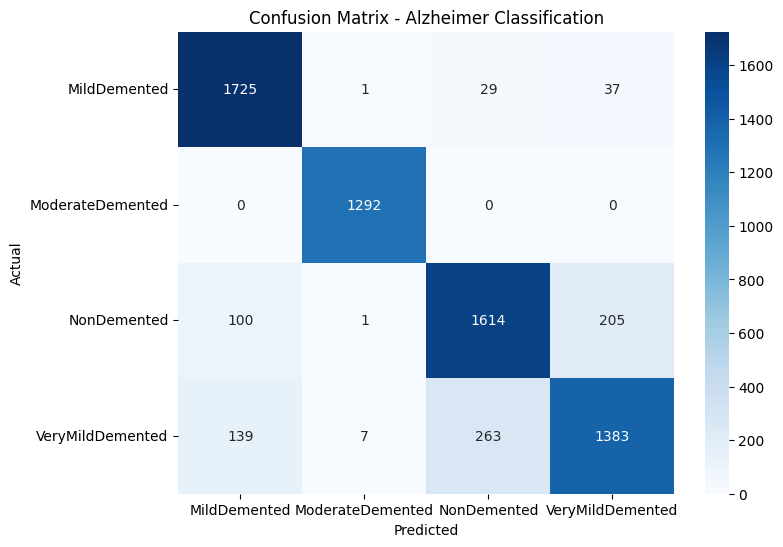

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
class_names = list(val_data_eval.class_indices.keys())

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Alzheimer Classification")
plt.show()

In [15]:
model.save("/content/alzheimer_final_model.keras")

In [20]:
from tensorflow.keras.preprocessing import image
import numpy as np
import tensorflow as tf

model = tf.keras.models.load_model("/content/alzheimer_final_model.keras")

class_names = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224,224))
    img_array = image.img_to_array(img)

    from tensorflow.keras.applications.efficientnet import preprocess_input
    img_array = preprocess_input(img_array)

    img_array = np.expand_dims(img_array, axis=0)

    preds = model.predict(img_array)

    predicted_class = class_names[np.argmax(preds)]
    confidence = np.max(preds)

    print("Prediction:", predicted_class)
    print("Confidence:", confidence)

# test
predict_image("/content/alzheimers_dataset/AugmentedAlzheimerDataset/VeryMildDemented/0073c8fe-469d-4160-9344-37d61ac6f9bd.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Prediction: VeryMildDemented
Confidence: 0.799614
